# CA6127 Member A — Dataset + Generation
Set **Runtime → Change runtime type → GPU** first. Run the cells one by one up to the end of Step 2, then choose the final sample size based on the measured speed.
Code, data, images and logs are written directly to `CA6127_project/` on Google Drive; re-running after a disconnect resumes automatically.

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
!nvidia-smi

Sat Oct 10 09:35:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             15W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [7]:
from google.colab import drive
drive.mount('/content/drive')
import os
WORK='/content/drive/MyDrive/CA6127_project'
os.makedirs(WORK+'/src',exist_ok=True)
%cd $WORK

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/.shortcut-targets-by-id/18-xxrEv08QY4Ka68hUjRkNVgnb6hktum/CA6127_project


In [8]:
!pip -q install diffusers transformers accelerate

In [9]:
%%writefile src/prepare_data.py
"""
Step 1 (Member A): build the evaluation subset from COCO 2017 val.

Output:
  data/captions.json        [{prompt_id, image_id, caption, file_name, seed}, ...]
  data/images/<file_name>   reference images (used by member B for FID)

Usage (Colab):
  python src/prepare_data.py --n 200          # formal run
  python src/prepare_data.py --n 50           # quick pipeline test
"""
import argparse, json, os, random, urllib.request, zipfile

ANN_URL = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"
IMG_URL = "http://images.cocodataset.org/val2017/{}"


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--n", type=int, default=200)
    ap.add_argument("--seed", type=int, default=42)
    ap.add_argument("--out", default="data")
    args = ap.parse_args()

    os.makedirs(f"{args.out}/images", exist_ok=True)
    ann_json = f"{args.out}/captions_val2017.json"

    # 1. download caption annotations (~240MB zip, only once)
    if not os.path.exists(ann_json):
        zpath = f"{args.out}/annotations.zip"
        print("Downloading COCO annotations ...")
        urllib.request.urlretrieve(ANN_URL, zpath)
        with zipfile.ZipFile(zpath) as z:
            with z.open("annotations/captions_val2017.json") as src, open(ann_json, "wb") as dst:
                dst.write(src.read())
        os.remove(zpath)

    coco = json.load(open(ann_json))
    id2file = {im["id"]: im["file_name"] for im in coco["images"]}

    # 2. one caption per image (first one), fixed random sample
    caps = {}
    for a in coco["annotations"]:
        caps.setdefault(a["image_id"], a["caption"].strip())
    image_ids = sorted(caps)
    random.Random(args.seed).shuffle(image_ids)
    chosen = image_ids[: args.n]

    # 3. save subset + download reference images
    records = []
    for i, img_id in enumerate(chosen):
        fname = id2file[img_id]
        path = f"{args.out}/images/{fname}"
        if not os.path.exists(path):
            urllib.request.urlretrieve(IMG_URL.format(fname), path)
        records.append({
            "prompt_id": i,
            "image_id": img_id,
            "caption": caps[img_id],
            "file_name": fname,
            "seed": 1000 + i,          # per-prompt seed, identical across samplers
        })
        if (i + 1) % 50 == 0:
            print(f"  {i + 1}/{args.n}")

    json.dump(records, open(f"{args.out}/captions.json", "w"), indent=2)
    print(f"Saved {len(records)} samples to {args.out}/captions.json")


if __name__ == "__main__":
    main()


Overwriting src/prepare_data.py


In [10]:
%%writefile src/generate.py
"""
Step 2 (Member A): generate images with Stable Diffusion v1.5 under different samplers.
Everything is fixed (model / prompt / seed / 512x512 / CFG / steps) except the scheduler.

Output:
  results/images/<sampler>_s<steps>/<prompt_id>.png
  results/generation_log.csv   (one row per image, appended; safe to resume)

Usage (Colab, GPU runtime):
  # Exp 1: three samplers, 30 steps
  python src/generate.py --samplers ddim euler dpmpp --steps 30
  # quick test
  python src/generate.py --samplers ddim euler dpmpp --steps 30 --limit 5
  # Member B can reuse it for the steps experiment
  python src/generate.py --samplers dpmpp --steps 10 20 40 50
"""
import argparse, csv, json, os, time

import torch
import diffusers, transformers
from diffusers import (StableDiffusionPipeline, DDIMScheduler,
                       EulerDiscreteScheduler, DPMSolverMultistepScheduler)

MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"


def make_scheduler(name, base_config):
    if name == "ddim":
        return DDIMScheduler.from_config(base_config)
    if name == "euler":
        return EulerDiscreteScheduler.from_config(base_config)
    if name == "dpmpp":  # DPM++ 2M Karras
        return DPMSolverMultistepScheduler.from_config(
            base_config, algorithm_type="dpmsolver++", solver_order=2, use_karras_sigmas=True)
    # --- ablation: separate the solver from the Karras noise schedule ---
    if name == "dpmpp_nokarras":  # DPM++ 2M with the model's default schedule
        return DPMSolverMultistepScheduler.from_config(
            base_config, algorithm_type="dpmsolver++", solver_order=2, use_karras_sigmas=False)
    if name == "euler_karras":  # Euler with the Karras schedule
        return EulerDiscreteScheduler.from_config(base_config, use_karras_sigmas=True)
    raise ValueError(name)


FIELDS = ["prompt_id", "image_id", "prompt", "seed", "sampler", "steps", "cfg",
          "height", "width", "gen_time_s", "image_path"]


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default="data/captions.json")
    ap.add_argument("--out", default="results")
    ap.add_argument("--samplers", nargs="+", default=["ddim", "euler", "dpmpp"])
    ap.add_argument("--steps", nargs="+", type=int, default=[30])
    ap.add_argument("--cfg", type=float, default=7.5)
    ap.add_argument("--size", type=int, default=512)
    ap.add_argument("--limit", type=int, default=None, help="only first N prompts (testing)")
    args = ap.parse_args()

    records = json.load(open(args.data))[: args.limit]

    pipe = StableDiffusionPipeline.from_pretrained(
        MODEL_ID, torch_dtype=torch.float16, safety_checker=None, requires_safety_checker=False
    ).to("cuda")
    pipe.set_progress_bar_config(disable=True)
    base_config = pipe.scheduler.config

    log_path = f"{args.out}/generation_log.csv"
    os.makedirs(args.out, exist_ok=True)
    new_file = not os.path.exists(log_path)
    # rows already logged -> only these count as "done" when resuming (no duplicate rows,
    # and an image saved without a log row gets regenerated)
    done = set()
    if not new_file:
        for row in csv.DictReader(open(log_path)):
            done.add((row["sampler"], int(row["steps"]), int(row["prompt_id"])))
    logf = open(log_path, "a", newline="")
    writer = csv.DictWriter(logf, fieldnames=FIELDS)
    if new_file:
        writer.writeheader()

    for sampler in args.samplers:
        pipe.scheduler = make_scheduler(sampler, base_config)
        # warm-up so the first timed image isn't slowed by CUDA init
        pipe("warm up", num_inference_steps=5, height=args.size, width=args.size)

        for steps in args.steps:
            folder = f"{args.out}/images/{sampler}_s{steps}"
            os.makedirs(folder, exist_ok=True)
            # record the full run config; refuse to resume into a folder made with different settings
            run_cfg = {
                "model_id": MODEL_ID, "sampler": sampler, "steps": steps, "cfg": args.cfg,
                "height": args.size, "width": args.size, "dtype": "float16", "safety_checker": None,
                "data": args.data,
                "scheduler_class": type(pipe.scheduler).__name__,
                "scheduler_config": dict(pipe.scheduler.config),
                "versions": {"torch": torch.__version__, "diffusers": diffusers.__version__,
                             "transformers": transformers.__version__},
                "gpu": torch.cuda.get_device_name(0),
                "timing_scope": "pipeline call only (text encoding + denoising + VAE decode); "
                                "excludes model loading and image saving; per-sampler warm-up",
            }
            cfg_path = f"{folder}/run_config.json"
            if os.path.exists(cfg_path):
                old = json.load(open(cfg_path))
                for k in ["model_id", "sampler", "steps", "cfg", "height", "width", "scheduler_class", "data"]:
                    if old.get(k) != run_cfg[k]:
                        raise SystemExit(f"Config mismatch in {folder}: {k} {old.get(k)} != {run_cfg[k]}")
            else:
                json.dump(run_cfg, open(cfg_path, "w"), indent=2, default=str)
            print(f"== {sampler} | {steps} steps | {len(records)} prompts")

            for r in records:
                img_path = f"{folder}/{r['prompt_id']:04d}.png"
                if (sampler, steps, r["prompt_id"]) in done and os.path.exists(img_path):
                    continue  # resume support
                g = torch.Generator("cuda").manual_seed(r["seed"])
                torch.cuda.synchronize(); t0 = time.perf_counter()
                img = pipe(r["caption"], num_inference_steps=steps, guidance_scale=args.cfg,
                           height=args.size, width=args.size, generator=g).images[0]
                torch.cuda.synchronize(); dt = time.perf_counter() - t0
                img.save(img_path)
                writer.writerow({
                    "prompt_id": r["prompt_id"], "image_id": r["image_id"], "prompt": r["caption"],
                    "seed": r["seed"], "sampler": sampler, "steps": steps, "cfg": args.cfg,
                    "height": args.size, "width": args.size, "gen_time_s": round(dt, 4),
                    "image_path": img_path,
                })
                logf.flush()

    logf.close()
    print("Done. Log:", log_path)


if __name__ == "__main__":
    main()


Overwriting src/generate.py


## 1. Prepare data (fixed random sample of 200 COCO val2017 image–caption pairs)

In [11]:
!python src/prepare_data.py --n 200

  50/200
  100/200
  150/200
  200/200
Saved 200 samples to data/captions.json


## 2. Pilot run: 5 prompts × 3 samplers (pipeline check + speed test)

In [12]:
!python src/generate.py --samplers ddim euler dpmpp --steps 30 --limit 5

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
model_index.json: 100% 541/541 [00:00<00:00, 2.45MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0% 0/13 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/308 [00:00<?, ?B/s]           

Fetching 13 files:  15% 2/13 [00:00<00:00, 17.84it/s]
Reconstructing (incomplete total...):  33% 308/925 [00:00<00:00, 2.77kB/s]
Reconstructing (incomplete total...):  22% 308/1.40k [00:00<00:00, 2.77kB/s]
Reconstructing (incomplete total...):   0% 1.40k/1.59M [00:00<03:54, 6.77kB/s]
Reconstructing (incomplete total...):   0% 1.40k/1.59M [00:00<03:54, 6.77kB/s]
Reconstructing (incomplete total...):   0% 1.74k/1.59M [00:00<03:01, 8.75kB/s]
Reconstructing (incomplete total...)

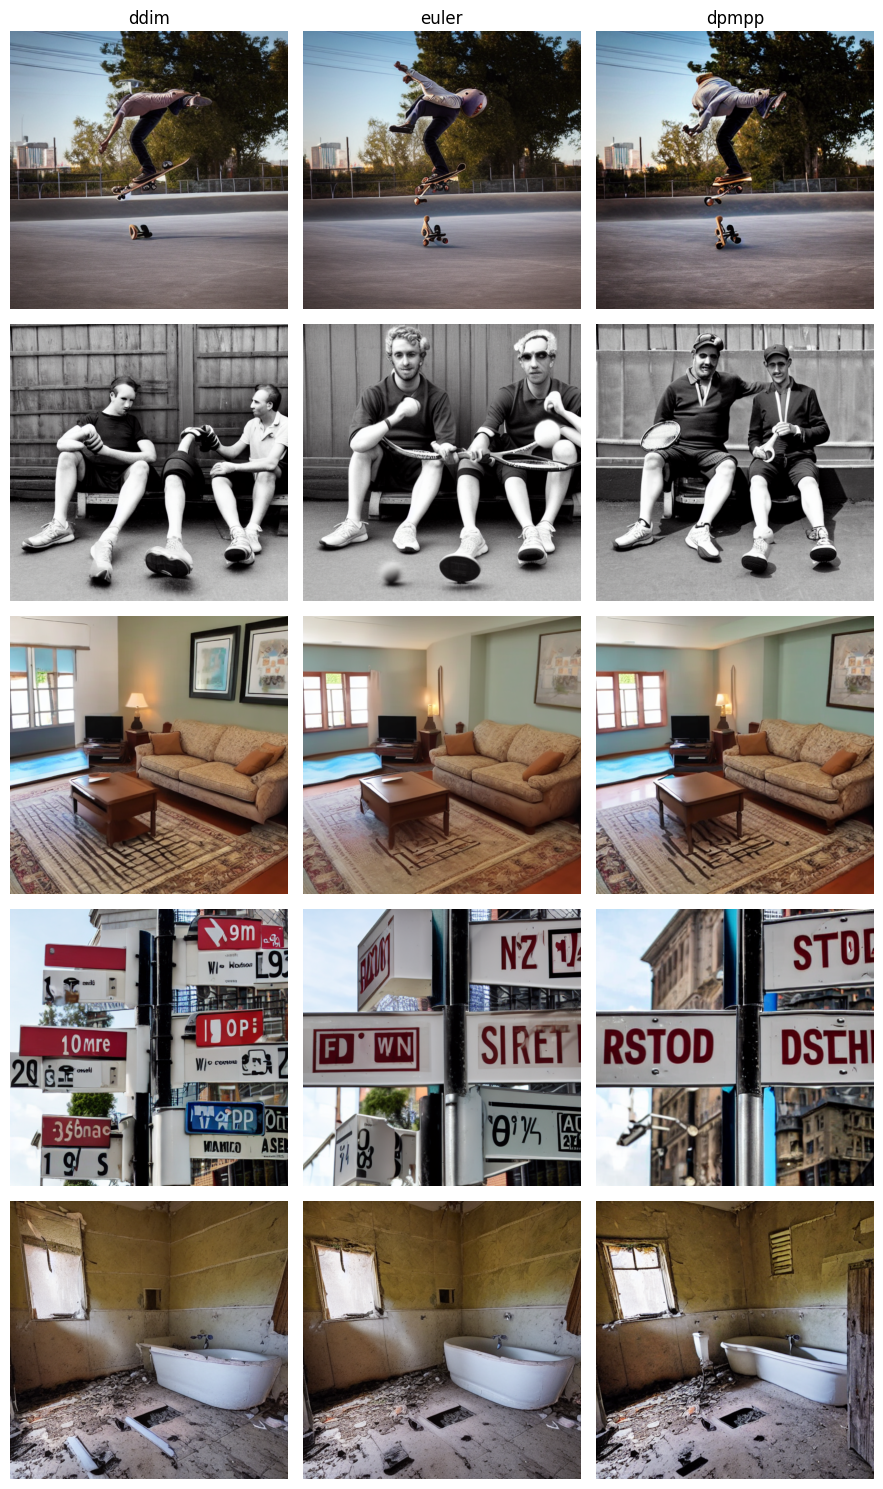

sampler
ddim              5.43
dpmpp             5.44
dpmpp_nokarras    5.35
euler             5.42
euler_karras      5.42
Name: gen_time_s, dtype: float64
100 prompts x 3 samplers ≈ 45 min (excluding loading/saving overhead)
200 prompts x 3 samplers ≈ 90 min (excluding loading/saving overhead)


In [13]:
from PIL import Image
import matplotlib.pyplot as plt, json, pandas as pd
caps=json.load(open('data/captions.json'))
S=['ddim','euler','dpmpp']
fig,ax=plt.subplots(5,3,figsize=(9,15))
for i in range(5):
    for j,s in enumerate(S):
        ax[i,j].imshow(Image.open(f'results/images/{s}_s30/{i:04d}.png')); ax[i,j].axis('off')
        if i==0: ax[i,j].set_title(s)
plt.tight_layout(); plt.show()
log=pd.read_csv('results/generation_log.csv')
per=log.groupby('sampler').gen_time_s.mean()
print(per.round(2))
for n in [100,200]:
    print(f'{n} prompts x 3 samplers ≈ {n*per.sum()/60:.0f} min (excluding loading/saving overhead)')

### Reproducibility check: regenerating with the same sampler and seed should reproduce the saved image
(images from different samplers are not expected to be identical)

In [14]:
import torch, numpy as np
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
pipe=StableDiffusionPipeline.from_pretrained('stable-diffusion-v1-5/stable-diffusion-v1-5',torch_dtype=torch.float16,safety_checker=None,requires_safety_checker=False).to('cuda')
pipe.scheduler=DPMSolverMultistepScheduler.from_config(pipe.scheduler.config,algorithm_type='dpmsolver++',solver_order=2,use_karras_sigmas=True)
r=caps[0]
img=pipe(r['caption'],num_inference_steps=30,guidance_scale=7.5,height=512,width=512,generator=torch.Generator('cuda').manual_seed(r['seed'])).images[0]
diff=np.abs(np.asarray(img,dtype=float)-np.asarray(Image.open('results/images/dpmpp_s30/0000.png'),dtype=float)).mean()
print('mean pixel diff:',round(diff,3),'→ OK' if diff<2 else '→ MISMATCH, check before the full run')
del pipe; torch.cuda.empty_cache()

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

mean pixel diff: 0.0 → OK


## 3. Full generation
Choose `N` (100 or 200) based on the speed test and keep it fixed. Images already generated in the pilot run are skipped automatically.

In [ ]:
N = 200
!python src/generate.py --samplers ddim euler dpmpp --steps 30 --limit $N

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...:  83% 5/6 [00:10<00:02,  2.38s/it]
Loading weights:   0% 0/196 [00:00<?, ?it/s]
Loading weights:   1% 2/196 [00:00<00:57,  3.40it/s]
Loading weights:  46% 90/196 [00:00<00:00, 169.54it/s]
Loading weights:  69% 136/196 [00:01<00:00, 163.00it/s]
Loading weights:  86% 168/196 [00:01<00:00, 150.16it/s]
Loading weights: 100% 196/196 [00:01<00:00, 137.44it/s]
Loading pipeline components...: 100% 6/6 [00:12<00:00,  2.01s/it]
== ddim | 30 steps | 200 prompts
== euler | 30 steps | 200 prompts
== dpmpp | 30 steps | 200 prompts
Done. Log: results/generation_log.csv


## 4. Output check

In [ ]:
import glob
log=pd.read_csv('results/generation_log.csv'); log=log[log.steps==30]
for s in S: print(s, len(glob.glob(f'results/images/{s}_s30/*.png')), 'images,', (log.sampler==s).sum(), 'log rows')
print('duplicate rows:', log.duplicated(['sampler','steps','prompt_id']).sum())
print(log.groupby('sampler').gen_time_s.agg(['count','mean','std']).round(3))

ddim 200 images, 200 log rows
euler 200 images, 200 log rows
dpmpp 200 images, 200 log rows
duplicate rows: 0
                count   mean    std
sampler                            
ddim              200  5.434  0.169
dpmpp             200  5.435  0.072
dpmpp_nokarras    200  5.348  0.241
euler             200  5.424  0.112
euler_karras      200  5.425  0.020


## 5. Ablation: solver vs. Karras noise schedule
DPM++ 2M Karras differs from the other samplers in both its solver and its noise schedule. To separate the two, we generate the same 200 prompts with two extra configurations:
- `dpmpp_nokarras`: DPM++ 2M with the model's default schedule (removes Karras from DPM++)
- `euler_karras`: Euler with the Karras schedule (adds Karras to Euler)

All other settings are identical to the main experiment (30 steps, CFG 7.5, same seeds).

In [ ]:
N = 200
!python src/generate.py --samplers dpmpp_nokarras euler_karras --steps 30 --limit $N

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...:  50% 3/6 [00:12<00:13,  4.57s/it]
Loading weights:   0% 0/196 [00:00<?, ?it/s]
Loading weights:   1% 2/196 [00:00<00:49,  3.89it/s]
Loading weights:  46% 90/196 [00:00<00:00, 188.17it/s]
Loading weights:  69% 136/196 [00:00<00:00, 171.75it/s]
Loading weights:  86% 168/196 [00:01<00:00, 154.30it/s]
Loading weights: 100% 196/196 [00:01<00:00, 144.84it/s]
Loading pipeline components...: 100% 6/6 [00:14<00:00,  2.38s/it]
== dpmpp_nokarras | 30 steps | 200 prompts
== euler_karras | 30 steps | 200 prompts
Done. Log: results/generation_log.csv


In [ ]:
import pandas as pd, glob
log = pd.read_csv('results/generation_log.csv'); log = log[log.steps == 30]
ALL = ['ddim', 'euler', 'euler_karras', 'dpmpp_nokarras', 'dpmpp']
for s in ALL:
    print(f"{s:15s}", len(glob.glob(f'results/images/{s}_s30/*.png')), 'images,', (log.sampler == s).sum(), 'log rows')
print('duplicate rows:', log.duplicated(['sampler', 'steps', 'prompt_id']).sum())
print(log.groupby('sampler').gen_time_s.agg(['count', 'mean', 'std']).reindex(ALL).round(3))

ddim            200 images, 200 log rows
euler           200 images, 200 log rows
euler_karras    200 images, 200 log rows
dpmpp_nokarras  200 images, 200 log rows
dpmpp           200 images, 200 log rows
duplicate rows: 0
                count   mean    std
sampler                            
ddim              200  5.434  0.169
euler             200  5.424  0.112
euler_karras      200  5.425  0.020
dpmpp_nokarras    200  5.348  0.241
dpmpp             200  5.435  0.072
